In [11]:
import pandas as pd
import os

# Pastikan kita di folder yang benar
os.chdir('/content')

print("Sedang membaca data (mohon tunggu 1-2 menit)...")

# Load data dengan encoding latin1 (sudah tidak pakai engine='python' agar lebih cepat)
df = pd.read_csv(
    'Base.csv',
    encoding='latin1',
    sep=','
)

print("[OK] Data berhasil dibaca!")
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

if 'fraud_bool' in df.columns:
    print("\nKolom 'fraud_bool' DITEMUKAN. Data siap diproses!")
    print(df[['month', 'fraud_bool']].head())
else:
    print("\n[ERROR] Kolom 'fraud_bool' TIDAK DITEMUKAN.")

Sedang membaca data (mohon tunggu 1-2 menit)...
[OK] Data berhasil dibaca!
Jumlah baris: 795923
Jumlah kolom: 32

Kolom 'fraud_bool' DITEMUKAN. Data siap diproses!
   month  fraud_bool
0    0.0           0
1    0.0           0
2    0.0           0
3    0.0           0
4    0.0           0


Time-Based Split & Cek Distribusi

In [12]:
# Reset index jika 'fraud_bool' terbaca sebagai index
if 'fraud_bool' not in df.columns and df.index.name == 'fraud_bool':
    df = df.reset_index()

# 1. Bagi data berdasarkan bulan
train_df = df[df['month'] < 3]
test_df = df[df['month'] == 3]

# 2. Pisahkan Fitur (X) dan Target (y)
X_train = train_df.drop(columns=['fraud_bool', 'month'])
y_train = train_df['fraud_bool']

X_test = test_df.drop(columns=['fraud_bool', 'month'])
y_test = test_df['fraud_bool']

# 3. Tampilkan hasil
print("=== HASIL SPLIT DATA ===")
print(f"Jumlah data latih (Train) : {len(X_train)} baris (Bulan 0-2)")
print(f"Jumlah data uji (Test)    : {len(X_test)} baris (Bulan 3)")

print("\n=== PERSENTASE PENIPU (FRAUD) ===")
print(f"Fraud di Train : {y_train.mean():.4%}")
print(f"Fraud di Test  : {y_test.mean():.4%}")

print(f"\nDimensi X_train: {X_train.shape}")
print(f"Dimensi X_test : {X_test.shape}")

=== HASIL SPLIT DATA ===
Jumlah data latih (Train) : 397039 baris (Bulan 0-2)
Jumlah data uji (Test)    : 150936 baris (Bulan 3)

=== PERSENTASE PENIPU (FRAUD) ===
Fraud di Train : 0.9813%
Fraud di Test  : 0.9222%

Dimensi X_train: (397039, 30)
Dimensi X_test : (150936, 30)


Training Model LightGBM

In [13]:
!pip install lightgbm -q

import lightgbm as lgb
import time

# 1. Ubah kolom teks (object) jadi 'category' agar LightGBM bisa membacanya
for col in X_train.select_dtypes(include=['object']).columns:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

print("Mulai melatih model LightGBM...")
start_time = time.time()

# 2. Definisikan model
model = lgb.LGBMClassifier(
    random_state=42,
    class_weight='balanced',
    n_estimators=100,
    learning_rate=0.1,
    n_jobs=-1,
    verbose=-1
)

# 3. Latih model
model.fit(X_train, y_train)

waktu_latih = time.time() - start_time
print(f"[OK] Training selesai dalam {waktu_latih:.2f} detik!")

Mulai melatih model LightGBM...
[OK] Training selesai dalam 8.33 detik!


Evaluasi & Grafik ROC (Mencari TPR pada FPR 5%).





=== HASIL EVALUASI (Data Test Bulan 3) ===
Target FPR   : 5.00%
FPR Aktual   : 4.9979%
TPR (Penipu tertangkap): 56.61%
Threshold yang dipakai : 0.8309


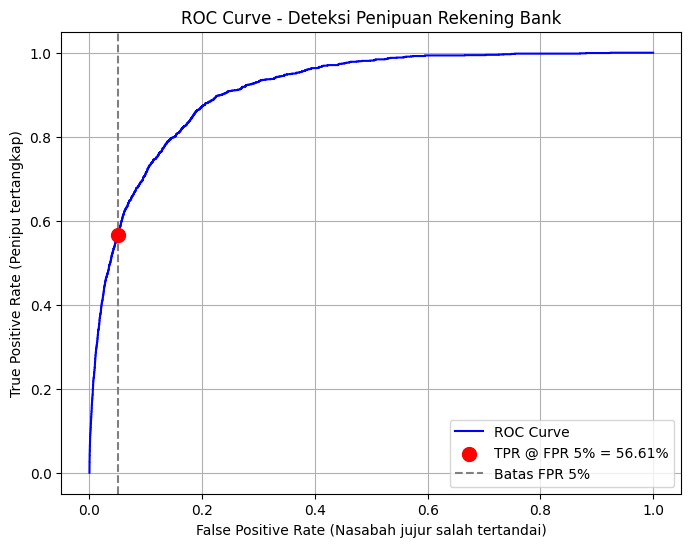

In [14]:
from sklearn.metrics import roc_curve
import numpy as np
import matplotlib.pyplot as plt

# 1. Prediksi probabilitas
y_probs = model.predict_proba(X_test)[:, 1]

# 2. Dapetin nilai FPR dan TPR
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# 3. Cari index yang FPR-nya paling dekat dengan 5% (0.05)
target_fpr = 0.05
idx = np.argmin(np.abs(fpr - target_fpr))

# 4. Ambil nilai TPR dan Threshold
tpr_at_5_fpr = tpr[idx]
threshold_at_5_fpr = thresholds[idx]

print("=== HASIL EVALUASI (Data Test Bulan 3) ===")
print(f"Target FPR   : 5.00%")
print(f"FPR Aktual   : {fpr[idx]:.4%}")
print(f"TPR (Penipu tertangkap): {tpr_at_5_fpr:.2%}")
print(f"Threshold yang dipakai : {threshold_at_5_fpr:.4f}")

# 5. Grafik ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label='ROC Curve')
plt.scatter(fpr[idx], tpr[idx], color='red', s=100, zorder=5,
            label=f'TPR @ FPR 5% = {tpr_at_5_fpr:.2%}')
plt.axvline(x=0.05, color='gray', linestyle='--', label='Batas FPR 5%')
plt.xlabel('False Positive Rate (Nasabah jujur salah tertandai)')
plt.ylabel('True Positive Rate (Penipu tertangkap)')
plt.title('ROC Curve - Deteksi Penipuan Rekening Bank')
plt.legend()
plt.grid(True)
plt.show()

Simpan Model & Bukti Load Ulang

In [15]:
import joblib
import os

# 1. Simpan model
os.makedirs('models', exist_ok=True)
model_path = 'models/baf_fraud_model.pkl'
joblib.dump(model, model_path)
print(f"[OK] Model berhasil disimpan di: {model_path}")

# 2. Bukti model bisa dimuat ulang
print("\nMenguji muat ulang model...")
loaded_model = joblib.load(model_path)
sample_pred = loaded_model.predict_proba(X_test.iloc[:5])
print("Prediksi probabilitas 5 data pertama (setelah di-load ulang):")
print(sample_pred)
print("\n[OK] Sukses! Model aman dan bisa digunakan kembali.")

[OK] Model berhasil disimpan di: models/baf_fraud_model.pkl

Menguji muat ulang model...
Prediksi probabilitas 5 data pertama (setelah di-load ulang):
[[0.03393226 0.96606774]
 [0.98638119 0.01361881]
 [0.98291227 0.01708773]
 [0.92544379 0.07455621]
 [0.7994721  0.2005279 ]]

[OK] Sukses! Model aman dan bisa digunakan kembali.


Download Model ke Laptop

In [17]:
from google.colab import files
files.download('models/baf_fraud_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Business Insight (Kesimpulan untuk Tim Risiko Bank)

Berdasarkan hasil evaluasi model LightGBM pada data validasi (Bulan 3), dengan menggunakan **threshold 0.8309**, model menunjukkan performa sebagai berikut:

- **Dari 100 penipu asli**, model berhasil mendeteksi dan memblokir **56 orang (56.61%)**.
- **Dari 100 nasabah jujur**, model hanya salah menuduh sebanyak **5 orang (FPR 4.9979%)**.

**Dampak Bisnis:**
Model ini sudah cukup efektif untuk membantu tim risiko dalam menangkap lebih dari separuh penipu. Tingkat *False Positive* (salah tuduh) yang berada di bawah batas 5% memastikan bahwa bank tidak akan kehilangan terlalu banyak calon pelanggan jujur, sekaligus menekan beban kerja tim verifikasi manual.

Untuk versi produksi, tim bank bisa menyesuaikan *threshold* ini tergantung pada prioritas bisnis: jika ingin lebih agresif menangkap penipu (TPR lebih tinggi), bank harus siap menerima FPR yang lebih tinggi (lebih banyak nasabah jujur yang harus diverifikasi manual).